In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Загрузка данных
df = pd.read_csv('../data/kyrgyzstan-food-prices.csv', skiprows=[1])

# Приведение даты к формату datetime
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year


In [ ]:
# Функция для расчета средней цены по годам, регионам и категориям продуктов
def average_price_per_year(df):
    return df.groupby(['year', 'admname', 'category'])['price'].mean().reset_index()

In [ ]:
def max_min_price_with_market(df):
    grouped = df.groupby(['admname', 'category' , 'year']).agg(
        max_price=('price', 'max'),
        min_price=('price', 'min'),
        max_market=('mktname', lambda x: df.loc[x.idxmax(), 'mktname']),
        min_market=('mktname', lambda x: df.loc[x.idxmin(), 'mktname'])
    ).reset_index()
    return grouped


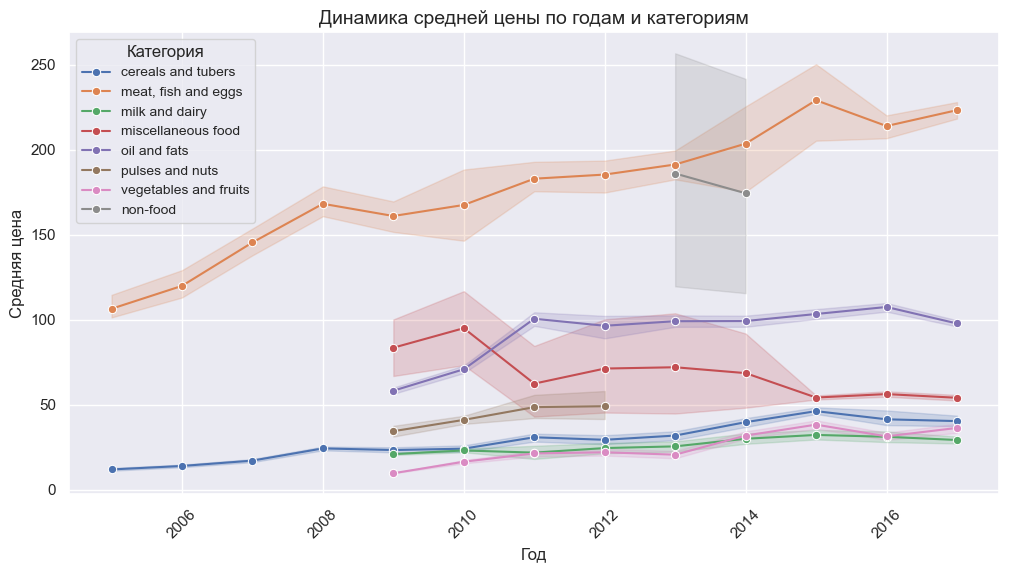

In [ ]:
# Установка стиля графика
sns.set(style='darkgrid')

# Расчёт средней цены по годам
avg_prices = average_price_per_year(df)

# Создание графика
plt.figure(figsize=(12, 6))
sns.lineplot(data=avg_prices, x='year', y='price', hue='category', marker='o')

# Настройки заголовков и подписей
plt.title('Динамика средней цены по годам и категориям', fontsize=14)
plt.xlabel('Год', fontsize=12)
plt.ylabel('Средняя цена', fontsize=12)
plt.xticks(rotation=45)  # Поворот подписей оси X для лучшей читаемости
plt.legend(title='Категория', fontsize=10)

# Сохранение и отображение графика
plt.savefig('average_price_trend.png', dpi=300, bbox_inches='tight')
plt.show()


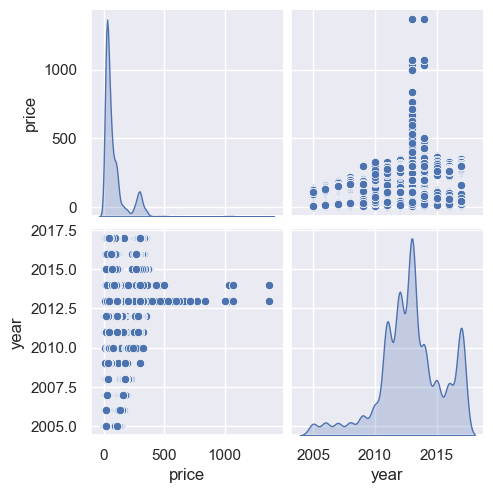

In [ ]:
# Парные графики
sns.pairplot(df[['price', 'year']], diag_kind='kde')
plt.savefig('pairplot.png')
plt.show()

In [ ]:
# Вызов функций
average_prices = average_price_per_year(df)
max_min_prices = max_min_price_with_market(df)

In [ ]:
# Сохранение результатов в CSV
average_prices.to_csv('average_prices.csv', index=False)
max_min_prices.to_csv('max_min_prices.csv', index=False)

print("Анализ завершен. Файлы сохранены.")

Анализ завершен. Файлы сохранены.


### Заключение